# 06 · Absolute Arithmetic

**Arithmetic Without Addition Lab**  |  Frobenius, finite-field zeta functions, and the limits of $q=1$

---

## From counting points to eigenvalues

For $X/\mathbb F_q$, encode counts $N_n=\# X(\mathbb F_{q^n})$ in
$$Z(X,T)=\exp\left(\sum_{n\ge1}\frac{N_nT^n}{n}\right).$$

For the projective line, $N_n=q^n+1$, so
$$Z(\mathbb P^1,T)=\frac1{(1-T)(1-qT)}.$$

An elliptic curve has a richer numerator:
$$Z(E,T)=\frac{1-aT+qT^2}{(1-T)(1-qT)},\quad a=q+1-\#E(\mathbb F_q).$$

The reciprocal roots of the numerator are Frobenius eigenvalues; they have absolute value $\sqrt q$ for a smooth elliptic curve. The calculation below tests finite-field counts against the Frobenius recurrence.

In [1]:
import sympy as sp
import matplotlib.pyplot as plt
from awa_lab.zeta import count_elliptic_fp, count_elliptic_fp2, frobenius_trace, elliptic_extension_counts, elliptic_zeta
p=5; a=1; b=1
N1=count_elliptic_fp(p,a,b)
N2=count_elliptic_fp2(p,a,b)
trace=frobenius_trace(p,N1)
counts=elliptic_extension_counts(p,N1,5)
print('Curve y^2=x^3+x+1 over F_5: N1=',N1,', N2=',N2)
print('Trace:',trace,'; predicted counts n=1,..,5:',counts)
print('Zeta function:',elliptic_zeta(p,N1))
assert counts[0]==N1 and counts[1]==N2
assert abs(trace)<=2*(p**.5)

Curve y^2=x^3+x+1 over F_5: N1= 9 , N2= 27
Trace: -3 ; predicted counts n=1,..,5: [9, 27, 108, 675, 3069]
Zeta function: (5*T**2 + 3*T + 1)/((1 - 5*T)*(1 - T))


## A trace with very little data

The Frobenius characteristic polynomial $u^2-au+q$ lets us compute $N_n$ recursively: if $s_n=\alpha^n+\beta^n$, then $s_0=2$, $s_1=a$, and $s_n=a s_{n-1}-q s_{n-2}$; hence $N_n=q^n+1-s_n$. A single point count over $\mathbb F_q$ predicts counts over every extension, once the elliptic-curve theorem is known.

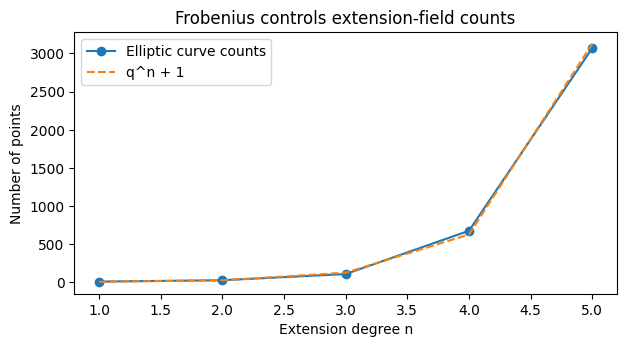

In [2]:
s=[2,trace]
for i in range(2,6): s.append(trace*s[-1]-p*s[-2])
assert all(counts[n-1]==p**n+1-s[n] for n in range(1,6))
fig,ax=plt.subplots(figsize=(7,3.4))
ax.plot(range(1,6),counts,marker='o',label='Elliptic curve counts')
ax.plot(range(1,6),[p**n+1 for n in range(1,6)],linestyle='--',label='q^n + 1')
ax.set(xlabel='Extension degree n',ylabel='Number of points',title='Frobenius controls extension-field counts')
ax.legend();plt.show()

## Why this touches the $\mathbb F_1$ dream

On varieties with polynomial point counts, formal evaluation at $q=1$ sometimes gives a combinatorial count: $\#\mathbb P^n(\mathbb F_q)=1+q+\cdots+q^n$ becomes $n+1$. The Grassmannian polynomial from Experiment 01 similarly becomes $\binom nk$.

**But do not set $q=1$ in an arbitrary zeta function and call it an absolute geometry.** Generic elliptic curves do not have one polynomial that counts points over all finite fields; even the finite-field curve and its coefficients depend on characteristic. The arithmetic-geometric ambition behind $\mathbb F_1$ is serious, while its formulations are nonunique and their claimed links to the classical Riemann hypothesis remain exploratory.

### Investigate

1. Derive the projective-line zeta function using $-\log(1-z)=\sum_{n\ge1}z^n/n$.
2. Find $\#E(\mathbb F_5)$ by counting solutions by hand; explain the point at infinity.
3. Deduce $N_2$ from $N_1$ without enumerating $\mathbb F_{25}$; then compare with the explicit field enumeration above.
4. Investigate where formal $q\to1$ specialization is legitimate for $\mathbb P^n$ and Grassmannians, and where it is not for elliptic curves.
5. Contrast the finite-field zeta-function zero constraints with the classical Riemann zeta function: what is a theorem, and what is a proposed analogy?